In [1]:

# Day 36: House Price Prediction and Market Analysis

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Sample dataset for practice
data = {
    "area_sqft": [800, 1000, 1200, 1500, 1800, 2000, 900, 1100,
                  1300, 1600, 1700, 2200, 950, 1250, 1450, 1900,
                  2100, 1050, 1550, 1750],
    "bedrooms": [2, 2, 3, 3, 3, 4, 2, 2, 3, 3,
                 3, 4, 2, 3, 3, 4, 4, 2, 3, 3],
    "bathrooms": [1, 2, 2, 2, 3, 3, 1, 2, 2, 2,
                  3, 3, 1, 2, 2, 3, 3, 2, 2, 3],
    "price_lakh": [20, 25, 32, 40, 48, 55, 22, 28,
                   35, 42, 46, 65, 23, 33, 38, 52,
                   60, 27, 41, 49]
}

df = pd.DataFrame(data)

print("Dataset Preview:")
display(df.head())

print("\nDataset Shape:", df.shape)


Dataset Preview:


,area_sqft,bedrooms,bathrooms,price_lakh
0,800,2,1,20
1,1000,2,2,25
2,1200,3,2,32
3,1500,3,2,40
4,1800,3,3,48



Dataset Shape: (20, 4)


In [2]:

# Select features and target
X = df[["area_sqft", "bedrooms", "bathrooms"]]
y = df["price_lakh"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict house prices
predictions = model.predict(X_test)

# Evaluate the model
print("Mean Absolute Error:", round(mean_absolute_error(y_test, predictions), 2), "lakh")
print("R2 Score:", round(r2_score(y_test, predictions), 2))

results = pd.DataFrame({
    "Actual Price (Lakh)": y_test.values,
    "Predicted Price (Lakh)": predictions.round(2)
})

display(results)


Mean Absolute Error: 1.7 lakh
R2 Score: 0.98


,Actual Price (Lakh),Predicted Price (Lakh)
0,20,22.87
1,27,27.69
2,52,54.04
3,25,26.18


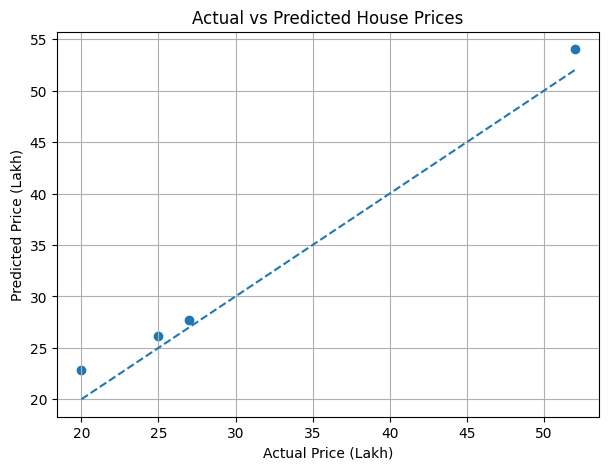

In [3]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, predictions)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Price (Lakh)")
plt.ylabel("Predicted Price (Lakh)")
plt.title("Actual vs Predicted House Prices")
plt.grid(True)
plt.show()


In [4]:

new_house = pd.DataFrame({
    "area_sqft": [1400],
    "bedrooms": [3],
    "bathrooms": [2]
})

predicted_price = model.predict(new_house)[0]

print("Area: 1400 sq. ft.")
print("Bedrooms: 3")
print("Bathrooms: 2")
print("Predicted House Price:", round(predicted_price, 2), "lakh")


Area: 1400 sq. ft.
Bedrooms: 3
Bathrooms: 2
Predicted House Price: 37.52 lakh


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Practice dataset
data = {
    "area_sqft": [800, 1000, 1200, 1500, 1800, 2000, 900, 1100,
                  1300, 1600, 1700, 2200, 950, 1250, 1450, 1900,
                  2100, 1050, 1550, 1750],
    "bedrooms": [2, 2, 3, 3, 3, 4, 2, 2, 3, 3,
                 3, 4, 2, 3, 3, 4, 4, 2, 3, 3],
    "bathrooms": [1, 2, 2, 2, 3, 3, 1, 2, 2, 2,
                  3, 3, 1, 2, 2, 3, 3, 2, 2, 3],
    "price_lakh": [20, 25, 32, 40, 48, 55, 22, 28,
                   35, 42, 46, 65, 23, 33, 38, 52,
                   60, 27, 41, 49]
}

df = pd.DataFrame(data)

X = df[["area_sqft", "bedrooms", "bathrooms"]]
y = df["price_lakh"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [6]:

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

display(importance)


,Feature,Importance
0,area_sqft,0.695738
2,bathrooms,0.153296
1,bedrooms,0.150966


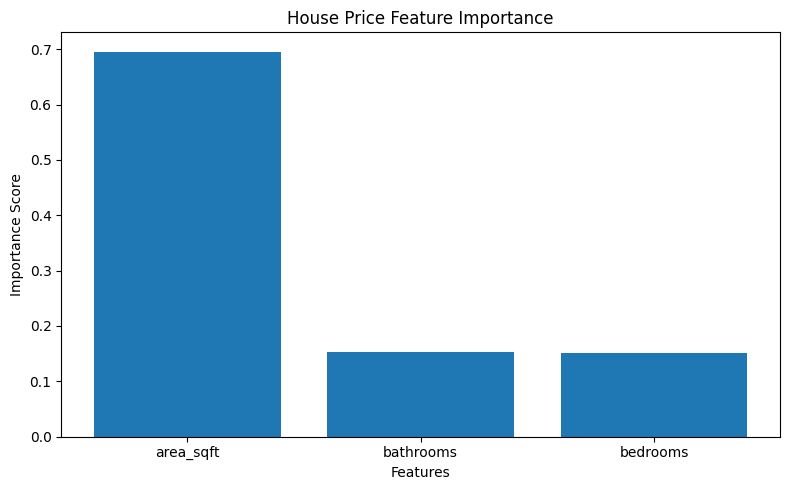

In [7]:

plt.figure(figsize=(8, 5))

plt.bar(importance["Feature"], importance["Importance"])

plt.title("House Price Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance Score")
plt.tight_layout()
plt.show()


In [8]:

top_feature = importance.iloc[0]["Feature"]

print("Most important feature:", top_feature)
print("\nDay 37 completed successfully!")


Most important feature: area_sqft

Day 37 completed successfully!
